# 偏振光学实验 —— 验证马吕斯定律

**原始数据**：偏振片偏转角 $\alpha$ 与透射光功率 $P$（mW）。

**处理思路**

1. 马吕斯定律 $I = I_0\cos^2\alpha$ 可改写为线性形式
   $$\frac{I}{I_0}=\cos^2\alpha$$
   令 $x=\cos^2\alpha$、$y=I/I_0$（$I_0$ 取 $\alpha=0^\circ$ 时的功率）。
2. 作 $I/I_0$ – $\cos^2\alpha$ 图并线性拟合，若 $y=a+bx$ 满足 $b\approx 1$、$a\approx 0$、$R^2\to1$，即验证马吕斯定律。
3. 图 1 为散点 + 线性拟合（Origin 版式），图 2 为同样的数据用线段连接（Line + Symbol）。

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.font_manager as fm

# ---------- 字体：英文用 Times New Roman，中文逐字回退到宋体 ----------
_installed = {f.name for f in fm.fontManager.ttflist}
_cjk_candidates = ['SimSun', 'STSong', 'Songti SC', 'Noto Serif SC',
                   'Source Han Serif SC', 'SimHei', 'Microsoft YaHei']
CJK_FONT = next((f for f in _cjk_candidates if f in _installed), 'DejaVu Sans')

# 注意：字体名必须直接写进 font.family 列表，matplotlib 才会逐字回退
rcParams['font.family']        = ['Times New Roman', CJK_FONT, 'DejaVu Sans']
rcParams['mathtext.fontset']   = 'stix'
rcParams['axes.unicode_minus'] = False
rcParams['figure.facecolor']   = 'white'
rcParams['savefig.facecolor']  = 'white'

pd.set_option('display.unicode.east_asian_width', True)

# ---------- 原始数据 ----------
alpha_deg = np.arange(0, 95, 5, dtype=float)          # 偏转角 α / (°)
P_mW = np.array([542.3, 536.7, 539.1, 521.2, 501.2,   # 功率 P / mW
                 464.1, 423.3, 386.1, 341.0, 287.2,
                 238.5, 191.2, 148.3, 114.2,  74.3,
                  45.1,  22.6,   7.8,   0.0])

# ---------- 数据处理 ----------
I0      = P_mW[0]                          # 最大光强 I0 (α = 0°)
cos_a   = np.cos(np.deg2rad(alpha_deg))    # cos α
cos2_a  = cos_a ** 2                       # cos²α
rel_I   = P_mW / I0                        # 相对光强 I/I0

df = pd.DataFrame({
    '偏转角 α/(°)':  alpha_deg.astype(int),
    'cos α':         cos_a,
    'cos²α':         cos2_a,
    '功率 P/(mW)':   P_mW,
    '相对光强 I/I₀': rel_I,
})
display(df.round(4))


def style_axes(ax):
    """统一坐标轴风格：四边框、刻度朝内、无网格（Origin 默认外观）。

    说明：含中文的文字不要混用 $...$ 数学模式，否则 matplotlib 会丢掉中文回退。
    这里用 Unicode 下标 ₀ 代替 $I_0$。
    """
    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(-0.05, 1.06)
    ax.set_xticks(np.arange(0.0, 1.01, 0.2))
    ax.set_yticks(np.arange(0.0, 1.01, 0.2))
    ax.tick_params(direction='in', length=4.5, width=0.9,
                   top=True, right=True, labelsize=11, pad=6)
    for sp in ax.spines.values():
        sp.set_linewidth(1.0)
    ax.set_xlabel(r'$\cos^{2}\alpha$', fontsize=14, labelpad=6)
    ax.set_ylabel('相对光强  I/I₀', fontsize=14, labelpad=8)


def add_table_box(ax, rows, col_widths, bbox):
    """Origin 风格信息框：白色底、细灰边框、文字左对齐。"""
    tbl = ax.table(cellText=rows, cellLoc='left',
                   colWidths=col_widths, bbox=bbox)
    tbl.auto_set_font_size(False)
    for cell in tbl.get_celld().values():
        cell.set_edgecolor('#808080')
        cell.set_linewidth(0.6)
        cell.set_facecolor('white')
        cell.get_text().set_fontsize(9.5)
    return tbl

,偏转角 α/(°),cos α,cos²α,功率 P/(mW),相对光强 I/I₀
0,0,1.0000,1.0000,542.3,1.0000
1,5,0.9962,0.9924,536.7,0.9897
2,10,0.9848,0.9698,539.1,0.9941
3,15,0.9659,0.9330,521.2,0.9611
4,20,0.9397,0.8830,501.2,0.9242
5,25,0.9063,0.8214,464.1,0.8558
6,30,0.8660,0.7500,423.3,0.7806
7,35,0.8192,0.6710,386.1,0.7120
8,40,0.7660,0.5868,341.0,0.6288
9,45,0.7071,0.5000,287.2,0.5296


拟合方程 : I/I0 = 0.0183 + 1.0086 · cos²α
斜率 b   = 1.0086 ± 0.0089
截距 a   = 0.0183 ± 0.0359
R² = 0.99868    Adj. R² = 0.99861


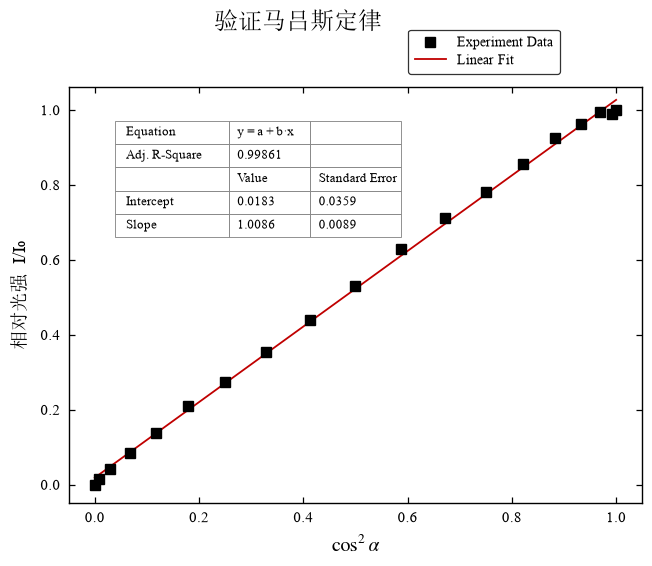

In [2]:
# ================= 图 1：散点 + 线性拟合（Origin 版式） =================
n      = len(cos2_a)
b, a   = np.polyfit(cos2_a, rel_I, 1)          # 拟合 y = a + b·x
y_hat  = a + b * cos2_a
ss_res = np.sum((rel_I - y_hat) ** 2)
ss_tot = np.sum((rel_I - rel_I.mean()) ** 2)
r2     = 1 - ss_res / ss_tot
adj_r2 = 1 - (1 - r2) * (n - 1) / (n - 2)

sxx  = np.sum((cos2_a - cos2_a.mean()) ** 2)
s    = np.sqrt(ss_res / (n - 2))
se_b = s / np.sqrt(sxx)                                   # 斜率标准误差
se_a = s / np.sqrt(1 / n + cos2_a.mean() ** 2 / sxx)      # 截距标准误差

print(f'拟合方程 : I/I0 = {a:.4f} + {b:.4f} · cos²α')
print(f'斜率 b   = {b:.4f} ± {se_b:.4f}')
print(f'截距 a   = {a:.4f} ± {se_a:.4f}')
print(f'R² = {r2:.5f}    Adj. R² = {adj_r2:.5f}')

fig, ax = plt.subplots(figsize=(7.4, 5.4))

# 实验点（黑色实心方块）
# 图例文字用英文：中文标签在内联预览的图例里可能丢字（不影响存图），英文各处都正常
ax.plot(cos2_a, rel_I, linestyle='none', marker='s', markersize=6.5,
        color='black', label='Experiment Data', zorder=3)

# 拟合直线
xx = np.linspace(0, 1, 200)
ax.plot(xx, a + b * xx, color='#C00000', linewidth=1.3,
        label='Linear Fit', zorder=2)

style_axes(ax)
ax.set_title('验证马吕斯定律', fontsize=17, x=0.40, pad=42)

leg = ax.legend(loc='lower left', bbox_to_anchor=(0.58, 1.015),
                fontsize=10, frameon=True, borderpad=0.5,
                labelspacing=0.35, handlelength=2.2)
leg.get_frame().set_linewidth(0.9)
leg.get_frame().set_edgecolor('black')

# ---- Origin 风格拟合结果框 ----
add_table_box(ax,
              rows=[['Equation',      'y = a + b·x',   ''],
                    ['Adj. R-Square', f'{adj_r2:.5f}', ''],
                    ['',              'Value',         'Standard Error'],
                    ['Intercept',     f'{a:.4f}',      f'{se_a:.4f}'],
                    ['Slope',         f'{b:.4f}',      f'{se_b:.4f}']],
              col_widths=[0.40, 0.28, 0.32],
              bbox=[0.08, 0.64, 0.50, 0.28])

plt.savefig('图1_散点+线性拟合.png', dpi=300, bbox_inches='tight')
plt.show()

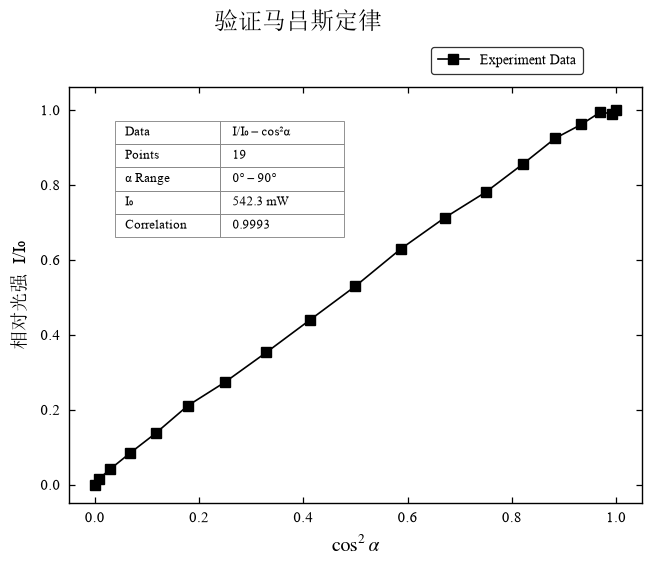

In [3]:
# ================= 图 2：散点 + 折线（Line + Symbol，不拟合） =================
order = np.argsort(cos2_a)                       # 按 cos²α 递增连线

fig2, ax2 = plt.subplots(figsize=(7.4, 5.4))
ax2.plot(cos2_a[order], rel_I[order], color='black', linewidth=1.2,
         marker='s', markersize=6.5, markerfacecolor='black',
         markeredgecolor='black', label='Experiment Data')

style_axes(ax2)
ax2.set_title('验证马吕斯定律', fontsize=17, x=0.40, pad=42)

leg2 = ax2.legend(loc='lower left', bbox_to_anchor=(0.62, 1.015),
                  fontsize=10, frameon=True, borderpad=0.5,
                  handlelength=2.2)
leg2.get_frame().set_linewidth(0.9)
leg2.get_frame().set_edgecolor('black')

# ---- Origin 风格数据信息框 ----
r_coef = np.corrcoef(cos2_a, rel_I)[0, 1]        # 相关系数
add_table_box(ax2,
              rows=[['Data',        'I/I₀ – cos²α'],
                    ['Points',      f'{len(cos2_a)}'],
                    ['α Range',     '0° – 90°'],
                    ['I₀',          f'{I0:.1f} mW'],
                    ['Correlation', f'{r_coef:.4f}']],
              col_widths=[0.46, 0.54],
              bbox=[0.08, 0.64, 0.40, 0.28])

plt.savefig('图2_折线图.png', dpi=300, bbox_inches='tight')
plt.show()

## 结果分析

- 数据点沿直线 $y=a+bx$ 分布，拟合斜率 $b\approx 1$、截距 $a\approx 0$，$\mathrm{Adj.}\ R^2$ 接近 1，
  说明透射光强与 $\cos^2\alpha$ 成正比，**马吕斯定律得到验证**。
- 截距不为零、个别点偏离，主要来自暗电流（零点未扣除）、偏振片消光比不为无穷大、
  角度读数与光轴对准误差等系统误差。
- 说明：$I_0$ 取 $\alpha=0^\circ$ 时的功率，若实验中对暗电流 $P_{\text{dark}}$ 做了扣除，
  应改用 $I = P - P_{\text{dark}}$ 重新计算。